In [2]:
""" Linear MOdels + Regularization Methods """

import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
from statsmodels.api import OLS
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from ISLP import load_data
from ISLP.models import ModelSpec as MS
from functools import partial
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from ISLP.models import (Stepwise, sklearn_selected, sklearn_selection_path)
from l0bnb import fit_path

In [3]:
""" Subset Selection Methods """

# reduce the number of parameters in a model by restricting the model to a subset of the input variables.
# Let's predict the baseball player salary with the assocaited with performance in the previous year.
# The np.isnan() function can be ued to identify the missing observations. It returns an array of the same shape as the input vector.
# The sum() method can then be used to count all of the missing elements.

Hitters = load_data('Hitters')
np.isnan(Hitters['Salary']).sum()


np.int64(59)

In [4]:
# The 'Salary' is missinh for 59 players. 
# The dropna() method of data frames removes all of the rows that have missing values in any variable

Hitters = Hitters.dropna();
Hitters.shape

(263, 20)

In [5]:
# Choose the best model using forward selection based on Cp
# define a function to compute it outselves and use it as a scorer.
# sklearn will try to maximize the score, hence our scoring function computes the negative Cp statistic.

def nCp(sigma2, estimator, X, Y):
    "Negative Cp statistics"
    n, p = X.shape
    Yhat = estimator.predict(X)
    RSS = np.sum((Y - Yhat) ** 2)
    return - (RSS + 2 * p * sigma2) / n

In [6]:
# Fit the biggest model, using all the variables and estimate o^2 based on its MSE

design = MS(Hitters.columns.drop('Salary')).fit(Hitters)
Y = np.array(Hitters['Salary'])
X = design.transform(Hitters)
sigma2 = OLS(Y, X).fit().scale

In [7]:
# Freeze the first argument with our estimate of o^2

neg_Cp = partial(nCp, sigma2)

In [8]:
# Now I can use neg_Cp() as a scorer for model selection
# Stepwise.first_peak() runs forward stepwise until any further additions to the model do not result in an improvement in the evaluation score.
# also, runs a fixed number of steps of stepwise search

strategy = Stepwise.first_peak(design, direction='forward', max_terms=len(design.terms))

In [9]:
# I can fit a linear regression model with 'Salary' as outcome using forward selection.
# This takes a model from statsmodels along with a search strategy and selects a model with its fit method.
# no specifying a scoring argument, the score defaults to MSE, and so all 19 variables will be selected...

hitters_MSE = sklearn_selected(OLS, strategy)
hitters_MSE.fit(Hitters, Y)
hitters_MSE.selected_state_


('Assists',
 'AtBat',
 'CAtBat',
 'CHits',
 'CHmRun',
 'CRBI',
 'CRuns',
 'CWalks',
 'Division',
 'Errors',
 'Hits',
 'HmRun',
 'League',
 'NewLeague',
 'PutOuts',
 'RBI',
 'Runs',
 'Walks',
 'Years')

In [10]:
# neg_Cp = results in a smaller model, as expected with just 10 variables selected

hitters_Cp = sklearn_selected(OLS, strategy, scoring=neg_Cp)
hitters_Cp.fit(Hitters, Y)
hitters_Cp.selected_state_

('Assists',
 'AtBat',
 'CAtBat',
 'CRBI',
 'CRuns',
 'CWalks',
 'Division',
 'Hits',
 'PutOuts',
 'Walks')

In [11]:
""" Choosing Among Models Using the Validation Set Approach and Cross-Validation """

# I need a methid that stores the full path of models found in forward selection.
# and allow prdictions for each of these
# sklearn_selection_path() estimator fron ISLP.models.
# cross_val_predict() computes the cross-validated predictions for each of the models along the path.
# which we can ue to evaluate the cross-validated MSE along the path.

# Selects the model at each step based on the biggest reduction in RSS.

strategy = Stepwise.fixed_steps(design, len(design.terms), direction='forward')
full_path = sklearn_selection_path(OLS, strategy)

In [12]:
# Fit the full forward-selection path on the Hitters data and compute the fitted values.

full_path.fit(Hitters, Y)
Yhat_in = full_path.predict(Hitters)
Yhat_in.shape

(263, 20)

(50000.0, 250000.0)

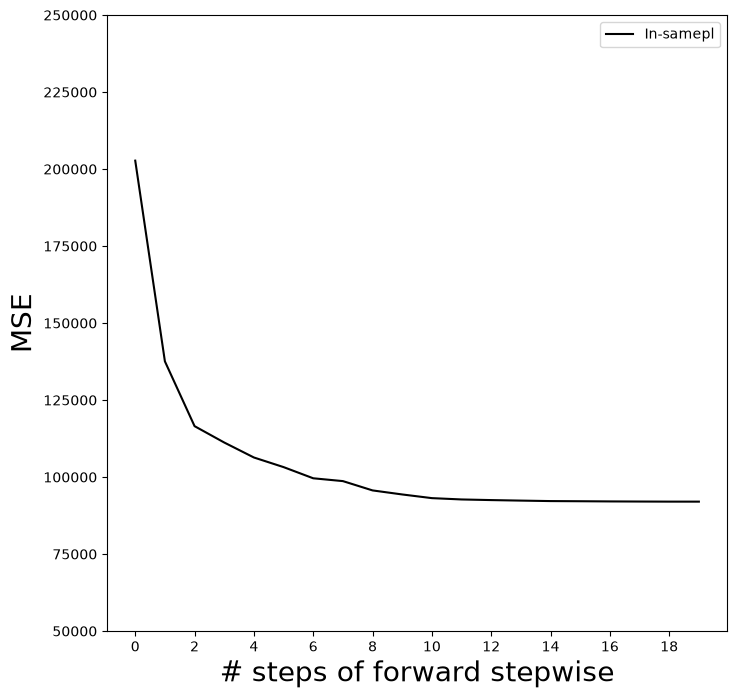

In [13]:
# The in-sample MSE improves each step we take, indicating we must use either the validation or cross-validation approach to select the number of steps.
# Let's fix the y-axis to range from 50,000 to 250,000 to compare to the cross-valiation and validation set MSE and other methods.

mse_fig, ax = subplots(figsize=(8, 8))
insample_mse = ((Yhat_in - Y[:, None]) ** 2).mean(0)
n_steps = insample_mse.shape[0]
ax.plot(np.arange(n_steps), insample_mse, 'k', label='In-samepl')
ax.set_ylabel('MSE', fontsize=20)
ax.set_xlabel('# steps of forward stepwise', fontsize=20)
ax.set_xticks(np.arange(n_steps)[::2])
ax.legend()
ax.set_ylim([50000, 250000]) 

In [14]:
# Now, I am ready to use cross-validation to estimate test error along the model path.
# We must use only the training observations to perform all aspects of model-fitting including variable selection.
# The determination of whcih model of a given size is best must be made using only the training observations in each training fold.
# If the full data set is used to select the best subset at each step, then the validation set errors and cross-validation errors that we obtain will not be accurate estimates of the test error.
# We not compute the cross-validation predcited values using 5-fold cross-validation

K = 5
kfold = skm.KFold(K, random_state=0, shuffle=True)
Yhat_cv = skm.cross_val_predict(full_path, Hitters, Y, cv=kfold)
Yhat_cv.shape

(263, 20)

In [15]:
# Yhat_cv = Yhat_in
# but the predictions in each row, corresponding to a particular sample index,
# were made from models fit on a training fold that did not include that row.

# Compute the MSE in each of the cross-validation folds.
# Then average to get the mean MSe and can also use the individual values to compute a crude estimate of the standard error of the mean.

# The random_state above, when we split any array with the same number of rows as Y we recover the same training and test indices.
# I just simply ignore the training indices below

cv_mse = []
for train_idx, test_idx in kfold.split(Y):
    errors = (Yhat_cv[test_idx] - Y[test_idx, None]) ** 2
    cv_mse.append(errors.mean(0)) # column means
cv_mse = np.array(cv_mse).T
cv_mse.shape

(20, 5)

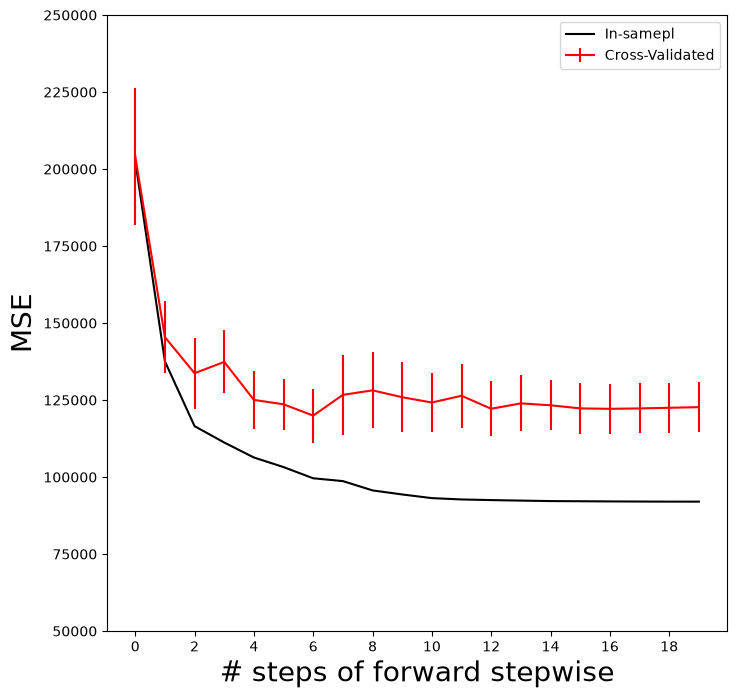

In [16]:
# We now add the cross-validation error estimates to our MSE plot.
# We include the mean error across the five folds, and the estimate of the standard error of the mean

ax.errorbar(np.arange(n_steps), cv_mse.mean(1), cv_mse.std(1) / np.sqrt(K), label='Cross-Validated', c='r') 
ax.set_ylim([50000, 250000])
ax.legend()
mse_fig

In [17]:
# To repeat the above using the validation set approach, we simply change our cv argument to a validation set.
# One random split of the data into a test and training.
# Let's choose a test size of 20% similar to the sie of each test set in 5-fold cross-validation.

validation = skm.ShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
for train_idx, test_idx in validation.split(Y):
    full_path.fit(Hitters.iloc[train_idx], Y[train_idx])
    Yhat_val = full_path.predict(Hitters.iloc[test_idx])
    errors = (Yhat_val - Y[test_idx, None]) ** 2
    validation_mse = errors.mean(0)

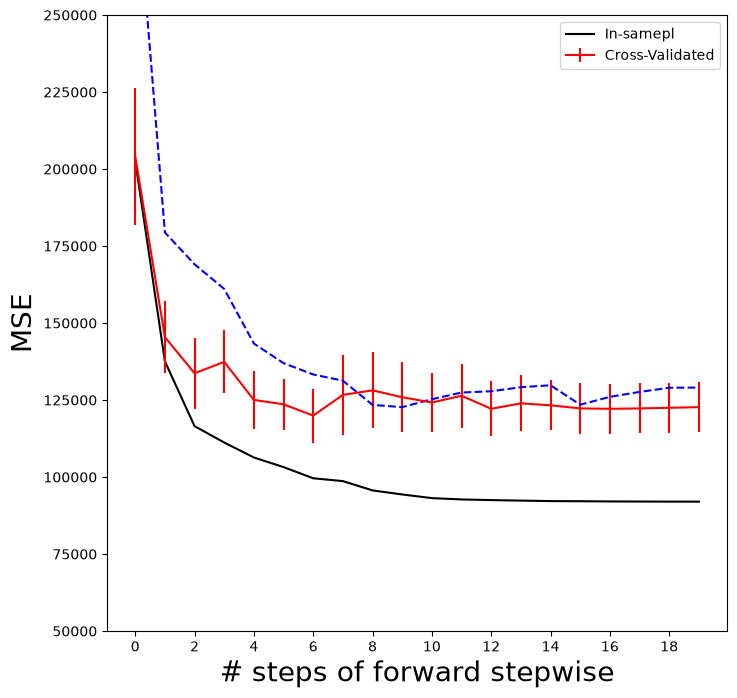

In [18]:
# As for the in-sample MSE case, the validation set approach does not provide standard errors.

ax.plot(np.arange(n_steps), validation_mse, 'b--') # blue broken line
ax.set_xticks(np.arange(n_steps)[::2])
ax.set_ylim([50000, 250000])
ax.legend()
mse_fig

In [19]:
""" Best Subset Selection """

# Forward stepwise is a greedy selection procedure; at each step it augments the current set by including one additional variable.
# Now apply best subset selection to the Hitters data, which for every subset size, searches for the best set of predictors.

# l0nb to perform best subset selection.
# This package produces a path of solutions using the subset size as a penalty rather than a constraint.
# Although the distinction is subtle, the difference comes when we cross-validate

D = design.fit_transform(Hitters)
D = D.drop('intercept', axis=1)
X = np.array(D)

In [20]:
# Here we excluded the first column corresponding to the intercept,
# as lonb will fit the intercept seprately.
# We can find a path using the fit_path() function.

path = fit_path(X, Y, max_nonzeros=X.shape[1])

Preprocessing Data.
BnB Started.
Iteration: 1. Number of non-zeros:  1
Iteration: 2. Number of non-zeros:  2
Iteration: 3. Number of non-zeros:  2
Iteration: 4. Number of non-zeros:  2
Iteration: 5. Number of non-zeros:  3
Iteration: 6. Number of non-zeros:  3
Iteration: 7. Number of non-zeros:  4
Iteration: 8. Number of non-zeros:  9
Iteration: 9. Number of non-zeros:  9
Iteration: 10. Number of non-zeros:  9
Iteration: 11. Number of non-zeros:  9
Iteration: 12. Number of non-zeros:  9
Iteration: 13. Number of non-zeros:  9
Iteration: 14. Number of non-zeros:  9
Iteration: 15. Number of non-zeros:  9
Iteration: 16. Number of non-zeros:  9
Iteration: 17. Number of non-zeros:  9
Iteration: 18. Number of non-zeros:  17
Iteration: 19. Number of non-zeros:  19


In [21]:
path[3]

{'B': array([0.        , 3.25484367, 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.67775265, 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        ]),
 'B0': np.float64(-38.98216739555494),
 'lambda_0': np.float64(0.011416248027450202),
 'M': np.float64(0.5829861733382009),
 'Time_exceeded': False}

In [22]:
# Above,
# I see that at the fourth step in the path, I have 2 nonzero coefficient in 'B'
# Corresponding to the value 0.114 for the penalty parameter lambda_0.
# I could make predictions using this sequence of fits on a validation set as a function of lambda_0 or with more work using cross-validation!

In [ ]:
""" Ridge Regression and the Lasso """